# Практическая работа №1–2: парная линейная регрессия

## Задание

1. Загрузить `Гиперспектр кукурузы.csv`.
2. Аналитически найти коэффициенты парной линейной регрессии и построить график.
3. Найти коэффициенты методом градиентного спуска и построить кривую обучения.
4. Сравнить прогнозы и оценить качество моделей.

> Значения `Spectr` умножаются на `0.001` ровно один раз. Это обязательное масштабирование данных сохранено во всех расчётах.

## Теория: парная линейная регрессия

Парная линейная регрессия использует один входной признак $x$ и один числовой ответ $Y$:

$$\hat{Y}_i=a_0+a_1x_i,$$

где $\hat{Y}_i$ — прогноз, $a_0$ — свободный коэффициент, $a_1$ — наклон прямой.

Отклонение прогноза от правильного ответа называется остатком:

$$e_i=Y_i-\hat{Y}_i.$$

Коэффициенты выбираются методом наименьших квадратов — минимизацией средней квадратичной ошибки:

$$MSE(a_0,a_1)=\frac{1}{n}\sum_{i=1}^{n}(Y_i-a_0-a_1x_i)^2.$$

Масштабирование $Y$ на `0.001` умножает $a_0$, $a_1$, MAE и RMSE на `0.001`, а MSE — на $0.001^2$. Форма зависимости и $R^2$ не меняются.

In [1]:
# Path нужен для безопасной работы с путём к CSV.
from pathlib import Path

# NumPy выполняет векторные математические операции.
import numpy as np
# Pandas загружает и показывает табличные данные.
import pandas as pd
# Matplotlib строит графики.
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda value: f'{value:.10g}')

In [2]:
DATA_FILE = Path('Гиперспектр кукурузы.csv')
if not DATA_FILE.exists():
    raise FileNotFoundError(f'Файл не найден: {DATA_FILE.resolve()}')

gipers = pd.read_csv(DATA_FILE, sep=';')

# Удаляем только строки с пропусками в необходимых столбцах.
gipers = gipers.dropna(subset=['wavelength', 'Spectr']).copy()

# x — объясняющий признак, Y — целевая переменная.
x = gipers['wavelength'].to_numpy(dtype=float)
Y = gipers['Spectr'].to_numpy(dtype=float) * 0.001  # обязательное масштабирование

print(f'Объектов: {len(gipers)}')
print(f'wavelength: от {x.min():.2f} до {x.max():.2f}')
print(f'Spectr после * 0.001: от {Y.min():.8f} до {Y.max():.8f}')
gipers.head()

Объектов: 273
wavelength: от 397.32 до 1001.16
Spectr после * 0.001: от 0.00002000 до 0.00062000


,wavelength,Spectr
0,397.32,0.02
1,399.54,0.03
2,401.76,0.03
3,403.98,0.05
4,406.2,0.05


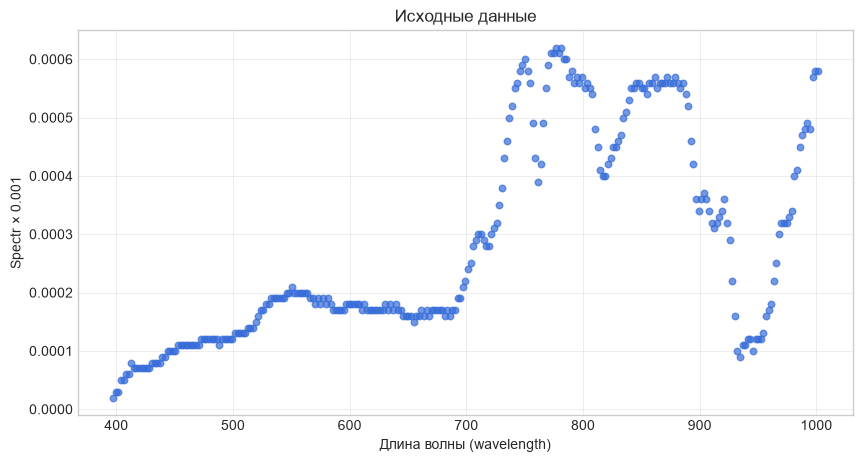

In [3]:
# Сначала смотрим на выборку без модели.
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(x, Y, s=22, alpha=0.7)
ax.set(
    title='Исходные данные',
    xlabel='Длина волны (wavelength)',
    ylabel='Spectr × 0.001',
)
plt.show()

## 1. Аналитическое решение

Минимум MSE для прямой можно найти без итераций:

$$a_1=\frac{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})(Y_i-\bar{Y})}
{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2},$$

$$a_0=\bar{Y}-a_1\bar{x}.$$

Числитель в формуле $a_1$ описывает совместное изменение $x$ и $Y$, знаменатель — разброс $x$. Это точное решение задачи наименьших квадратов для одного признака.

In [4]:
# Центрируем значения: вычитаем из каждого значения среднее.
x_centered = x - x.mean()
Y_centered = Y - Y.mean()

# По аналитическим формулам находим наклон a1 и свободный коэффициент a0.
a1_anal = np.mean(x_centered * Y_centered) / np.mean(x_centered ** 2)
a0_anal = Y.mean() - a1_anal * x.mean()

# Строим плотную сетку x для изображения прямой без изломов.
x_space = np.linspace(x.min(), x.max(), 300)
Y_pred_anal = a0_anal + a1_anal * x_space

# Отдельно считаем прогнозы в исходных точках для метрик качества.
Y_pred_anal_train = a0_anal + a1_anal * x
mse_anal = np.mean((Y - Y_pred_anal_train) ** 2)

print(f'Аналитическая модель: Ŷ = {a0_anal:.10f} + {a1_anal:.10e} · x')
print(f'MSE на обучающей выборке: {mse_anal:.10e}')

Аналитическая модель: Ŷ = -0.0001834278 + 6.6815502625e-07 · x
MSE на обучающей выборке: 1.7684114628e-08


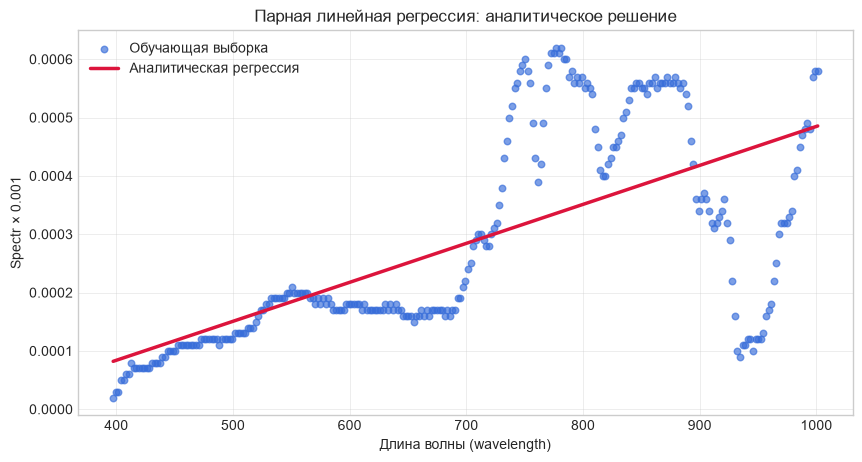

In [5]:
# Синие точки — наблюдения, красная линия — прогноз регрессии.
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(x, Y, s=22, alpha=0.65, label='Обучающая выборка')
ax.plot(x_space, Y_pred_anal, color='crimson', lw=2.5,
        label='Аналитическая регрессия')
ax.set(
    title='Парная линейная регрессия: аналитическое решение',
    xlabel='Длина волны (wavelength)',
    ylabel='Spectr × 0.001',
)
ax.legend()
plt.show()

## 2. Градиентный спуск

Градиентный спуск начинает с некоторых $a_0$ и $a_1$ и многократно двигает их в сторону уменьшения MSE:

$$a_0 \leftarrow a_0-\alpha\frac{\partial MSE}{\partial a_0}, \qquad
a_1 \leftarrow a_1-\alpha\frac{\partial MSE}{\partial a_1},$$

$$\frac{\partial MSE}{\partial a_0}=\frac{2}{n}\sum_{i=1}^{n}(\hat{Y}_i-Y_i),$$

$$\frac{\partial MSE}{\partial a_1}=\frac{2}{n}\sum_{i=1}^{n}(\hat{Y}_i-Y_i)x_i.$$

$\alpha$ — скорость обучения. Слишком большая $\alpha$ приводит к расходимости, слишком маленькая — к медленному обучению.

Чтобы масштаб `wavelength` не мешал оптимизации, используем стандартизацию

$$x'_i=\frac{x_i-\bar{x}}{s_x}.$$

Целевая переменная $Y$ при этом остаётся в масштабе `Spectr × 0.001`.

In [6]:
class SimpleRegression:
    """Парная линейная регрессия, обучаемая градиентным спуском."""

    def __init__(self):
        # Начальные параметры модели.
        self.a0 = 0.0
        self.a1 = 0.0
        self.n_iter_ = 0

    def predict(self, x):
        # Формула прямой Ŷ = a0 + a1*x.
        return self.a0 + self.a1 * np.asarray(x, dtype=float)

    def MSE(self, x, Y):
        # Средний квадрат ошибки.
        return np.mean((np.asarray(Y, dtype=float) - self.predict(x)) ** 2)

    def MAE(self, x, Y):
        # Средний модуль ошибки.
        return np.mean(np.abs(np.asarray(Y, dtype=float) - self.predict(x)))

    def MAPE(self, x, Y):
        # Средняя относительная ошибка в процентах.
        Y = np.asarray(Y, dtype=float)
        if np.any(Y == 0):
            raise ValueError('MAPE не определён при Y = 0')
        return np.mean(np.abs((Y - self.predict(x)) / Y)) * 100

    def fit(self, x, Y, alpha=0.1, tolerance=1e-20, max_steps=10_000):
        x = np.asarray(x, dtype=float)
        Y = np.asarray(Y, dtype=float)
        if x.shape != Y.shape:
            raise ValueError('x и Y должны иметь одинаковую форму')

        # Сохраняем начальную ошибку, чтобы затем построить кривую обучения.
        steps = [0]
        errors = [self.MSE(x, Y)]
        previous_error = errors[-1]

        for step in range(1, max_steps + 1):
            # residuals = прогноз - правильный ответ.
            residuals = self.predict(x) - Y

            # Производные MSE по двум параметрам. mean() реализует деление на n.
            gradient_a0 = 2 * residuals.mean()
            gradient_a1 = 2 * np.mean(residuals * x)

            # Делаем шаг в направлении, противоположном градиенту.
            self.a0 -= alpha * gradient_a0
            self.a1 -= alpha * gradient_a1

            current_error = self.MSE(x, Y)
            if not np.isfinite(current_error):
                raise FloatingPointError('Градиентный спуск разошёлся: уменьшите alpha')

            steps.append(step)
            errors.append(current_error)
            self.n_iter_ = step

            # Если MSE почти перестала изменяться, минимум уже достигнут.
            if abs(previous_error - current_error) < tolerance:
                break
            previous_error = current_error

        return np.asarray(steps), np.asarray(errors)

In [7]:
# Параметры стандартизации вычисляем по всей обучающей выборке.
x_mean = x.mean()
x_std = x.std() # стандартное отклонение
if np.isclose(x_std, 0.0):
    raise ValueError('Стандартное отклонение wavelength равно нулю')

x_norm = (x - x_mean) / x_std

# Обучаем модель на нормализованном x. Y уже имеет нужный множитель 0.001.
regr = SimpleRegression()
steps, errors = regr.fit(
    x_norm,
    Y,
    alpha=0.1,
    tolerance=1e-20,
    max_steps=10_000,
)

# Модель обучилась в координатах x'=(x-x_mean)/x_std.
# Переводим коэффициенты обратно, чтобы получить формулу через исходный x:
# a1_original = a1_normalized / x_std
# a0_original = a0_normalized - a1_original * x_mean
a1_gd = regr.a1 / x_std
a0_gd = regr.a0 - a1_gd * x_mean

Y_pred_gd = a0_gd + a1_gd * x_space
Y_pred_gd_train = a0_gd + a1_gd * x
mse_gd = np.mean((Y - Y_pred_gd_train) ** 2)

print(f'Число шагов: {regr.n_iter_}')
print(f'Модель градиентного спуска: Ŷ = {a0_gd:.10f} + {a1_gd:.10e} · x')
print(f'MSE на обучающей выборке: {mse_gd:.10e}')

Число шагов: 66
Модель градиентного спуска: Ŷ = -0.0001834278 + 6.6815475783e-07 · x
MSE на обучающей выборке: 1.7684114628e-08


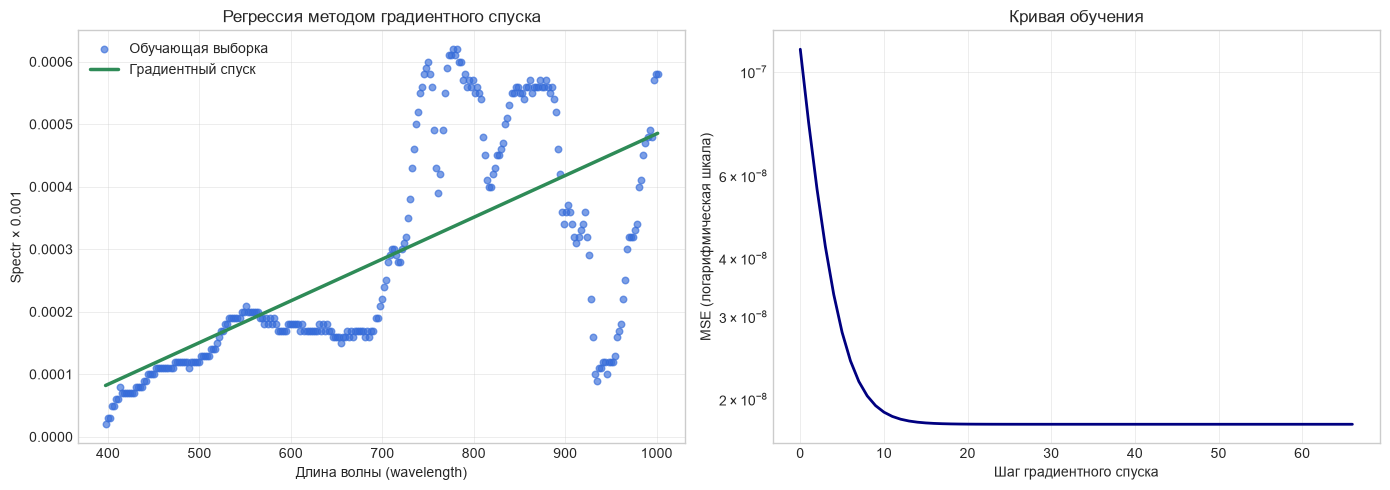

In [8]:
# Слева показываем модель, справа — уменьшение ошибки на каждой итерации.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(x, Y, s=22, alpha=0.65, label='Обучающая выборка')
axes[0].plot(x_space, Y_pred_gd, color='seagreen', lw=2.5,
             label='Градиентный спуск')
axes[0].set(
    title='Регрессия методом градиентного спуска',
    xlabel='Длина волны (wavelength)',
    ylabel='Spectr × 0.001',
)
axes[0].legend()

# Логарифмическая шкала помогает увидеть быстрое падение малых значений MSE.
axes[1].semilogy(steps, errors, color='navy', lw=2)
axes[1].set(
    title='Кривая обучения',
    xlabel='Шаг градиентного спуска',
    ylabel='MSE (логарифмическая шкала)',
)

plt.tight_layout()
plt.show()

## 3. Оценка качества

Используем несколько метрик:

$$MSE=\frac{1}{n}\sum_{i=1}^{n}(Y_i-\hat{Y}_i)^2,$$

$$RMSE=\sqrt{MSE}, \qquad MAE=\frac{1}{n}\sum_{i=1}^{n}|Y_i-\hat{Y}_i|,$$

$$MAPE=\frac{100\%}{n}\sum_{i=1}^{n}\left|\frac{Y_i-\hat{Y}_i}{Y_i}\right|,$$

$$R^2=1-\frac{\sum(Y_i-\hat{Y}_i)^2}{\sum(Y_i-\bar{Y})^2}.$$

Чем меньше ошибки MSE, RMSE, MAE и MAPE, тем лучше. $R^2$ ближе к 1 означает, что модель объясняет большую долю изменчивости ответа.

In [9]:
def regression_metrics(y_true, y_pred):
    """Возвращает основные метрики регрессии."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    residuals = y_true - y_pred

    mse = np.mean(residuals ** 2)
    mae = np.mean(np.abs(residuals))
    mape = np.mean(np.abs(residuals / y_true)) * 100
    r2 = 1 - np.sum(residuals ** 2) / np.sum((y_true - y_true.mean()) ** 2)

    return {
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAE': mae,
        'MAPE, %': mape,
        'R²': r2,
    }


# Сравниваем обе модели на одних и тех же исходных объектах.
model_comparison = pd.DataFrame({
    'Аналитическая модель': regression_metrics(Y, Y_pred_anal_train),
    'Градиентный спуск': regression_metrics(Y, Y_pred_gd_train),
}).T

print('Метрики качества:')
display(model_comparison)
print('Разница коэффициентов:')
print(f'|Δa0| = {abs(a0_anal - a0_gd):.10e}')
print(f'|Δa1| = {abs(a1_anal - a1_gd):.10e}')

Метрики качества:


,MSE,RMSE,MAE,"MAPE, %",R²
Аналитическая модель,1.768411463e-08,0.0001329816327,9.683443702e-05,43.37699902,0.4358912573
Градиентный спуск,1.768411463e-08,0.0001329816327,9.683442563e-05,43.37697262,0.4358912573


Разница коэффициентов:
|Δa0| = 7.3689288449e-11
|Δa1| = 2.6842093294e-13


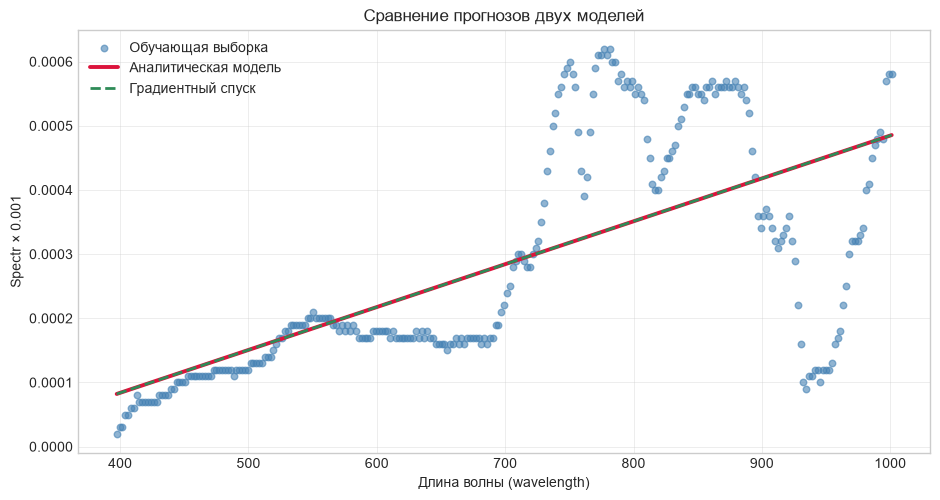

In [10]:
# Линии должны практически совпасть: оба метода минимизируют одну MSE.
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(x, Y, s=22, alpha=0.6, color='steelblue',
           label='Обучающая выборка')
ax.plot(x_space, Y_pred_anal, color='crimson', lw=2.8,
        label='Аналитическая модель')
ax.plot(x_space, Y_pred_gd, color='seagreen', lw=2, ls='--',
        label='Градиентный спуск')
ax.set(
    title='Сравнение прогнозов двух моделей',
    xlabel='Длина волны (wavelength)',
    ylabel='Spectr × 0.001',
)
ax.legend()
plt.show()

In [11]:
print('Вывод:')
print(
    'Градиентный спуск сошёлся к аналитическому решению: '
    f'MSE моделей различается на {abs(mse_anal - mse_gd):.3e}, '
    f'|Δa0|={abs(a0_anal - a0_gd):.3e}, '
    f'|Δa1|={abs(a1_anal - a1_gd):.3e}.'
)
print(
    f'R² = {model_comparison.loc["Аналитическая модель", "R²"]:.3f}. '
    'Линейная модель объясняет часть изменчивости Spectr, '
    'но зависимость в данных заметно нелинейная.'
)

Вывод:
Градиентный спуск сошёлся к аналитическому решению: MSE моделей различается на 1.520e-20, |Δa0|=7.369e-11, |Δa1|=2.684e-13.
R² = 0.436. Линейная модель объясняет часть изменчивости Spectr, но зависимость в данных заметно нелинейная.
